In [39]:
import pandas as pd
df  = pd.read_parquet("../outputs/processed/ais_cleaned.parquet")
df.head()

,date,cell_ll_lat,cell_ll_lon,mmsi,hours,fishing_hours,file_year,file_month,year,month,day
0,2012-02-26,13.8,80.3,419900160.0,11.9516,11.9516,2012,2,2012,2,26
1,2012-02-27,13.3,80.4,419900160.0,11.7252,11.7252,2012,2,2012,2,27
2,2012-02-25,15.2,80.7,419900160.0,11.7252,11.7252,2012,2,2012,2,25
3,2012-02-26,14.4,80.5,419900160.0,11.7166,11.7166,2012,2,2012,2,26
4,2012-02-25,14.4,80.6,419900160.0,10.4722,10.4722,2012,2,2012,2,25


In [41]:
START_YEAR = 2018
df = df.loc[df["year"] >= START_YEAR].copy()
print("Name \t \t Rows\n", df.count())
print("Date range:", df.date.min(), "→", df.date.max())
print("Years:", sorted(df["year"].unique().tolist()))
df.head()

Name 	 	 Rows
 date             718974
cell_ll_lat      718974
cell_ll_lon      718974
mmsi             718974
hours            718974
fishing_hours    718974
file_year        718974
file_month       718974
year             718974
month            718974
day              718974
dtype: int64
Date range: 2018-01-01 00:00:00 → 2024-12-31 00:00:00
Years: [2018, 2019, 2020, 2021, 2022, 2023, 2024]


,date,cell_ll_lat,cell_ll_lon,mmsi,hours,fishing_hours,file_year,file_month,year,month,day
11514,2018-01-03,17.9,72.5,419068318.0,18.2000,18.2000,2018,1,2018,1,3
11515,2018-01-02,18.2,72.5,419839101.0,17.1274,17.1274,2018,1,2018,1,2
11516,2018-01-02,17.5,72.5,419067318.0,16.7052,16.7052,2018,1,2018,1,2
11517,2018-01-03,15.5,73.6,419101996.0,15.0813,14.7777,2018,1,2018,1,3
11518,2018-01-05,16.9,72.6,419341821.0,14.6033,14.6033,2018,1,2018,1,5


In [45]:
filtered = df[
    (df["year"] == 2018) &
    (df["month"] == 1) &
    (df["day"] == 1)
]

print(filtered.to_string())
print("Total rows:", filtered.shape[0])

            date  cell_ll_lat  cell_ll_lon         mmsi    hours  fishing_hours  file_year  file_month  year  month  day
11523 2018-01-01         18.3         72.3  419067318.0  12.2794        12.2794       2018           1  2018      1    1
11526 2018-01-01         17.0         73.2  419901387.0  21.0052        10.9597       2018           1  2018      1    1
11528 2018-01-01         18.6         72.4  419901250.0  11.1116        10.6508       2018           1  2018      1    1
11530 2018-01-01         17.2         72.7  419901519.0  12.6558        10.3586       2018           1  2018      1    1
11532 2018-01-01         19.4         72.1  419901250.0  10.7647        10.1288       2018           1  2018      1    1
11533 2018-01-01         18.9         72.3  419901470.0  10.0963        10.0963       2018           1  2018      1    1
11541 2018-01-01         18.7         72.5  419901482.0  10.0097         9.1880       2018           1  2018      1    1
11544 2018-01-01         15.0   

In [26]:
MONTH = 1
df_month = df[df["month"] == MONTH].copy()

print("Records:", len(df_month))
print(df_month.groupby("year").size())

Records: 51438
year
2018     1092
2019     3557
2020     2246
2021     1941
2022    12788
2023    17090
2024    12724
dtype: int64


In [27]:
monthly_cells = (
    df_month.groupby(
        ["year", "cell_ll_lat", "cell_ll_lon"],
        as_index=False
    )
    .agg(
        fishing_hours=("fishing_hours", "sum")
    )
)

print(monthly_cells.head())

   year  cell_ll_lat  cell_ll_lon  fishing_hours
0  2018          9.7         75.5         3.9227
1  2018          9.8         75.4        12.1851
2  2018          9.8         75.5         6.2561
3  2018          9.8         76.0         0.1575
4  2018         12.2         74.8        29.8046


In [28]:
import numpy as np

CELL_SIZE = 0.1

LON_MIN, LON_MAX = 65, 100
LAT_MIN, LAT_MAX = 0, 38

lon_edges = np.arange(
    LON_MIN, LON_MAX + CELL_SIZE / 2, CELL_SIZE
)

lat_edges = np.arange(
    LAT_MIN, LAT_MAX + CELL_SIZE / 2, CELL_SIZE
)

ncols = len(lon_edges) - 1
nrows = len(lat_edges) - 1

In [29]:
grids = {}

for year in range(2018, 2025):

    subset = monthly_cells[monthly_cells["year"] == year]

    grid = np.full((nrows, ncols), np.nan)

    lon_idx = np.rint(
        (subset["cell_ll_lon"].to_numpy() - LON_MIN)
        / CELL_SIZE
    ).astype(int)

    lat_idx = np.rint(
        (subset["cell_ll_lat"].to_numpy() - LAT_MIN)
        / CELL_SIZE
    ).astype(int)

    valid = (
        (lon_idx >= 0) & (lon_idx < ncols)
        & (lat_idx >= 0) & (lat_idx < nrows)
    )

    grid[lat_idx[valid], lon_idx[valid]] = (
        subset["fishing_hours"].to_numpy()[valid]
    )

    grids[year] = grid

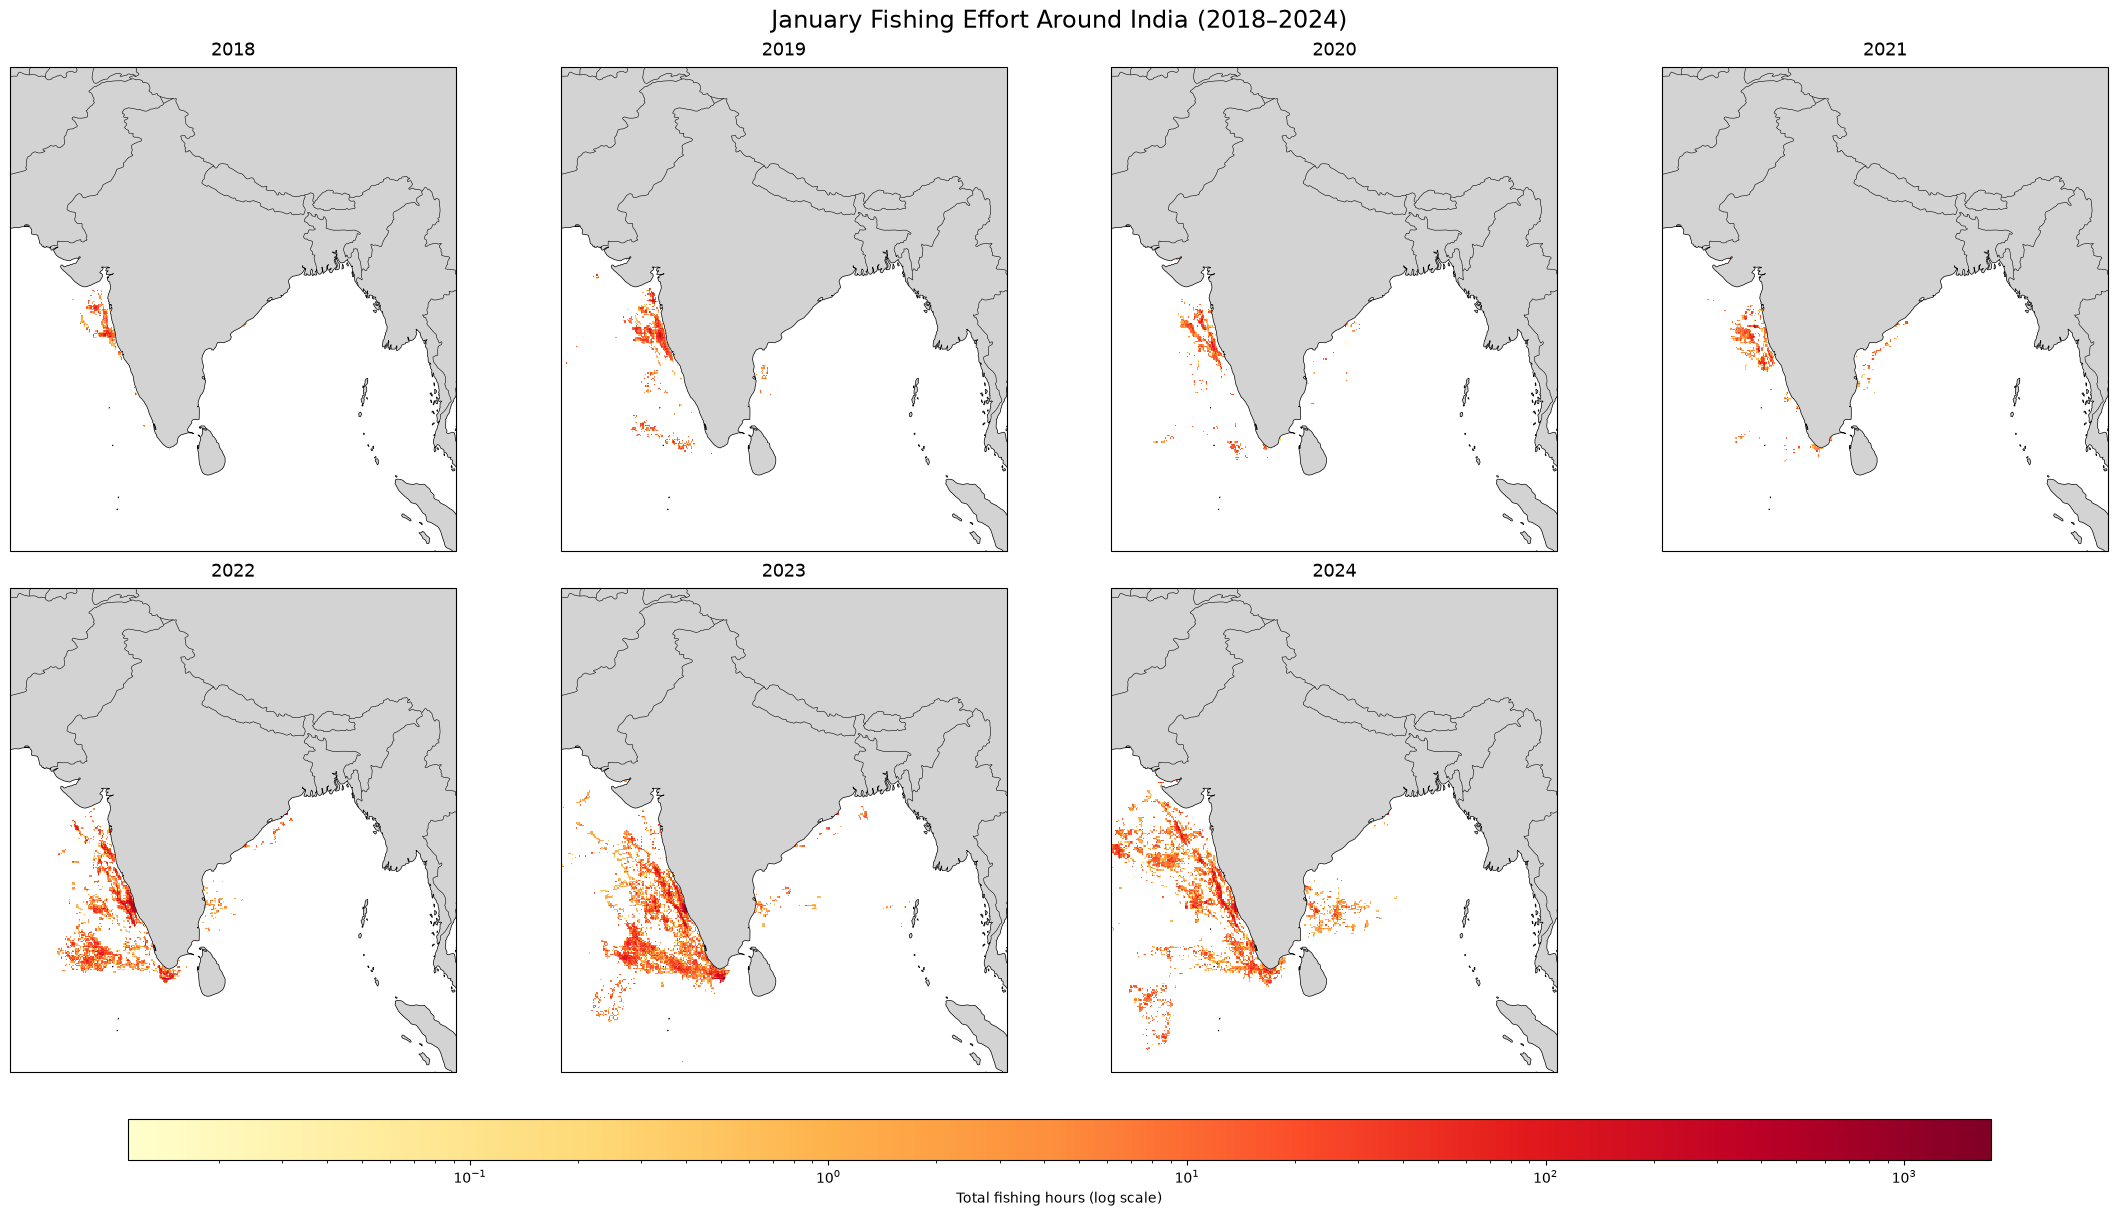

In [33]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Find the positive values across all seven years.
all_values = np.concatenate([
    grid[np.isfinite(grid) & (grid > 0)]
    for grid in grids.values()
])

if len(all_values) == 0:
    raise ValueError("No positive fishing hours found.")

# One shared color scale makes year-to-year comparisons fair.
vmin = all_values.min()
vmax = all_values.max()

if vmin == vmax:
    vmin /= 10
    vmax *= 10

norm = colors.LogNorm(vmin=vmin, vmax=vmax)

fig, axes = plt.subplots(
    2,
    4,
    figsize=(22, 12),
    constrained_layout=True,
    subplot_kw={"projection": ccrs.PlateCarree()}
)
axes = axes.ravel()
mesh = None

for ax, year in zip(axes, range(2018, 2025)):
    ax.set_extent(
        [lon_edges[0], lon_edges[-1], lat_edges[0], lat_edges[-1]],
        crs=ccrs.PlateCarree()
    )
    ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=3)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4, zorder=3)

    # LogNorm cannot display zero or negative values, so mask them too.
    data = np.ma.masked_where(
        ~np.isfinite(grids[year]) | (grids[year] <= 0),
        grids[year]
    )

    mesh = ax.pcolormesh(
        lon_edges,
        lat_edges,
        data,
        cmap="YlOrRd",
        norm=norm,
        shading="flat",
        transform=ccrs.PlateCarree(),
        zorder=1
    )
    ax.set_title(str(year), fontsize=13, pad=8)

axes[-1].set_visible(False)
fig.suptitle(
    "January Fishing Effort Around India (2018–2024)",
    fontsize=17
)
fig.colorbar(
    mesh,
    ax=axes[:-1].tolist(),
    label="Total fishing hours (log scale)",
    orientation="horizontal",
    shrink=0.85,
    pad=0.04,
    aspect=45
)

fig.savefig(
    "../outputs/processed/january_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)